[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_news_impact/BA_L3_news_impact.ipynb)

# BA_L3_news_impact: News impact curves

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

News impact curves of GJR-GARCH(1,1) models with Student-t errors for the S&P 500 and Bitcoin, estimated on daily log returns from 2018 to 18 September 2026: today's volatility as a function of yesterday's shock, with a symmetric curve of the same average reaction for comparison.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** Daily log returns in %, 1 January 2018 – 18 September 2026 (S&P 500 on trading days, Bitcoin every day).

**Model.** GJR-GARCH(1,1)-t (Glosten, Jagannathan and Runkle, 1993):
$$ \sigma_t^2 = \omega + \big(\alpha + \gamma\,\mathbb 1\{\varepsilon_{t-1} < 0\}\big)\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 ; $$
$\gamma > 0$ is the leverage effect: falls raise volatility more than rises. We test $\gamma = 0$ by the likelihood ratio $\mathrm{LR} = 2(\ell_{\text{GJR}} - \ell_{\text{GARCH}}) \sim \chi^2_1$.

**How to read.** The news impact curve gives today's $\sigma_t$ (annualised, % a year) as a function of yesterday's shock $\varepsilon_{t-1}$, with yesterday's variance at its sample median.
Dashed red: the symmetric curve with the same average reaction $\alpha + \gamma/2$.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['S&P 500', 'Bitcoin']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'S&P 500': '2190 days, 2018-01-02 - 2026-09-18', 'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18'}


In [6]:
# GARCH(1,1) with Student-t errors, estimated by maximum likelihood (package arch)
fits = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
gjr = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, o=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
pd.DataFrame({k: {'mu': g.params['mu'], 'omega': g.params['omega'], 'alpha': g.params['alpha[1]'], 'beta': g.params['beta[1]'],
                   'alpha + beta': g.params['alpha[1]'] + g.params['beta[1]'], 'nu': g.params['nu']} for k, g in fits.items()}).round(4)

,S&P 500,Bitcoin
mu,0.1109,0.0563
omega,0.0352,0.1442
alpha,0.1616,0.0761
beta,0.8194,0.9239
alpha + beta,0.9810,1.0000
nu,5.8454,3.1260


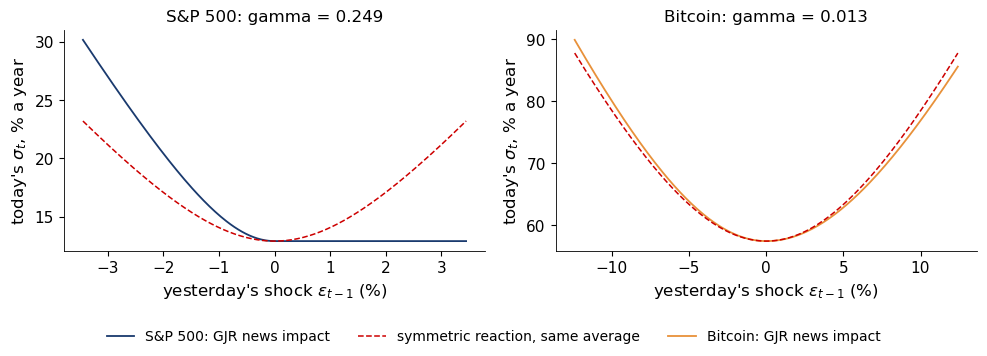

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
nic_rows = {}
for a_, k in [(ax[0], 'S&P 500'), (ax[1], 'Bitcoin')]:
    pj = gjr[k].params; A = ASSETS[k][1]
    s2 = np.median(gjr[k].conditional_volatility ** 2)
    nic = lambda e: pj['omega'] + (pj['alpha[1]'] + pj['gamma[1]'] * (e < 0)) * e ** 2 + pj['beta[1]'] * s2
    e = np.linspace(-4, 4, 201) * np.sqrt(s2)
    nic_s = pj['omega'] + (pj['alpha[1]'] + pj['gamma[1]'] / 2) * e ** 2 + pj['beta[1]'] * s2
    a_.plot(e, np.sqrt(nic(e) * A), color=ASSETS[k][2], label=f'{k}: GJR news impact')
    a_.plot(e, np.sqrt(nic_s * A), color=RED, ls='--', lw=1.1, label=('symmetric reaction, same average' if k == 'S&P 500' else None))
    a_.set_xlabel(r"yesterday's shock $\varepsilon_{t-1}$ (%)"); a_.set_ylabel(r"today's $\sigma_t$, % a year")
    a_.set_title(f"{k}: gamma = {pj['gamma[1]']:.3f}")
    LR = 2 * (gjr[k].loglikelihood - fits[k].loglikelihood)
    nic_rows[k] = {'gamma (GJR)': pj['gamma[1]'], 't(gamma)': gjr[k].tvalues['gamma[1]'], 'LR for gamma = 0': LR,
                   'p-value': stats.chi2.sf(LR, 1),
                   "today's volatility after a -3% day (% a year)": np.sqrt(nic(-3.0) * A),
                   "today's volatility after a +3% day (% a year)": np.sqrt(nic(3.0) * A)}
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, 'ba_l3_news_impact')

**Key numbers** (as on the slide).

In [8]:
pd.DataFrame(nic_rows).round(3)

,S&P 500,Bitcoin
gamma (GJR),0.249,0.013
t(gamma),6.252,0.721
LR for gamma = 0,75.892,0.685
p-value,0.000,0.408
today's volatility after a -3% day (% a year),27.023,59.807
today's volatility after a +3% day (% a year),12.892,59.436
